# Run SDM for Snowdon Beetle (*Chrysolina cerealis*): Random Forest

*Section 11 — Case study: species distribution modelling, notebook 4 of 5.* Previous: `03_maxent_species_distribution_modelling`. Next: `05_compare_sdm_models`.

This notebook models the Snowdon beetle a third time, with a **random forest**, the model used in the rsgispy species distribution modelling guide, again with the same training data as notebooks 02 and 03. Notebook 05 compares the three models.

**What a random forest is.** A random forest is an ensemble of classification trees. Each tree repeatedly splits the samples on a threshold of one variable (e.g. "distance to ledges < 640 m") so that the groups it creates are as pure as possible (mostly presences, or mostly pseudo-absences). Each tree is grown on a bootstrap sample of the training data and considers only a random subset of the variables at each split; the forest's prediction is the average of its trees. Compared with the other two models:

* **Responses can take any shape**, without us choosing features (no quadratic term, no hinges): but they are **step-like** (the average of many step functions), and **flat beyond the training data**, since a tree cannot split outside the range it has seen.
* **Interactions are found automatically**: a tree that first splits on temperature and then on distance to ledges represents an interaction. This flexibility is also the main risk: with few presences, a random forest can learn the exact locations of the training sites (over-fitting), which random cross-validation does not detect.
* **No standardisation** is needed, and monotonic transformations of a variable (e.g. a logarithm of a distance) make no difference.
* **Class imbalance.** With many more pseudo-absences than presences, trees tend to predict "absent" everywhere. Barbet-Massin et al. (2012) recommend the same number of pseudo-absences as presences for tree models (often several replicate sets); here we keep the same training data as the other models, for a fair comparison, and weight the classes equally instead (`class_weight="balanced"`), as in the guide.

**You will learn:**
- how to fit and tune a random forest SDM (`min_samples_leaf`, `max_features`) with spatial cross-validation;
- why spatial cross-validation matters most for flexible models;
- how to interpret a random forest with response curves, jackknife importance, SHAP (`TreeExplainer`) and Sobol indices.

**Before you start:** run notebooks `01_prepare_datasets` and `02_species_distribution_modelling` (this notebook uses the training and test samples, and the scenario rasters, of notebook 02). Random forests are introduced in section 4 (`04_image_classification/03_supervised_pixel_classification`).

**Data:** from notebook 01: `outputs/Chrysolina_cerealis_presences.gpkg`, `outputs/valid_mask.tif`, `outputs/sdm_candidate_vars.json` and the images it lists. From notebook 02 (`outputs/sdm_LogReg_outs/`): `sdm_train.gpkg`, `sdm_test.gpkg` and the warmer temperature rasters `Mean_Winter_Temp_plus*.tif`.

**Run time:** about 2 minutes.

## Import Modules

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
from IPython.display import Image, display
from rsgispy.ml.cv import SpatialBlockKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

## Define the Input Data and Output Directories

The same seven variables, the same training and test samples (with raw values), and the same spatial splitter (1 km blocks, 3 folds) as notebooks 02 and 03.

In [2]:
out_dir = "outputs/sdm_RF_outs"
plots_dir = os.path.join(out_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)
lr_dir = "outputs/sdm_LogReg_outs"

presences_vec_file = "outputs/Chrysolina_cerealis_presences.gpkg"
presences_vec_lyr = "presences"
valid_msk_img = "outputs/valid_mask.tif"
cand_var_imgs = rsgispy.tools.jsonio.read_json_to_dict("outputs/sdm_candidate_vars.json")
env_vars = dict()
for var_name, img_file in cand_var_imgs.items():
    env_vars[var_name] = species_distribution.EnvVarInfo(
        name=var_name, file=img_file, band=1, data_type=rsgispy.VAR_TYPE_CONTINUOUS
    )
analysis_vars = [var_name for var_name in env_vars if var_name != "elevation"]

train_gdf = geopandas.read_file(os.path.join(lr_dir, "sdm_train.gpkg"), layer="train")
test_gdf = geopandas.read_file(os.path.join(lr_dir, "sdm_test.gpkg"), layer="test")
test_y = test_gdf["clsid"].to_numpy()
n_train_pres = int(train_gdf["clsid"].sum())
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
print("Training:", train_gdf["clsid"].value_counts().to_dict())
print("Test:    ", test_gdf["clsid"].value_counts().to_dict())

blk_cv = SpatialBlockKFold(n_splits=3, block_size=1000.0, stratify=True, rnd_seed=42)
train_xy = numpy.column_stack([train_gdf.geometry.x, train_gdf.geometry.y])
blk_splits = list(blk_cv.split(train_gdf[analysis_vars], train_gdf["clsid"], coords=train_xy))
print("Presences in each held-out fold:",
      [int(train_gdf["clsid"].iloc[test_idx].sum()) for _, test_idx in blk_splits])

Training: {0: 7000, 1: 23}
Test:     {0: 3000, 1: 11}
Presences in each held-out fold: [5, 7, 11]


## 1. Tune the Random Forest

Two hyperparameters control how closely a random forest follows the training data:

* `min_samples_leaf`: the minimum number of samples in a leaf (end node) of a tree. With 1, a tree can isolate a single presence, i.e. memorise a site; larger values give smoother, more general responses. Ecologically, it sets how many records must share a combination of conditions before the forest believes it.
* `max_features`: the number of variables a split may choose from (`"sqrt"`: 2–3 of the 7; `1.0`: all). Fewer variables make the trees more different from each other, and let weaker variables be used.

We use 500 trees (more only make the result more stable, not more flexible), and score by the spatial cross-validated AUC with the same 1 km blocks as before.

In [3]:
def make_rf_mdl(**params):
    return RandomForestClassifier(
        n_estimators=500, class_weight="balanced", n_jobs=-1, random_state=42, **params
    )


grid_space = {"min_samples_leaf": [1, 3, 10, 30, 100, 300], "max_features": ["sqrt", 1.0]}
search_obj = GridSearchCV(make_rf_mdl(), param_grid=grid_space, cv=blk_splits, scoring="roc_auc")
search_obj.fit(train_gdf[analysis_vars], train_gdf["clsid"])
cv_res_df = pandas.DataFrame(search_obj.cv_results_)[
    ["param_min_samples_leaf", "param_max_features", "mean_test_score", "std_test_score"]
]
cv_res_df.columns = ["min_samples_leaf", "max_features", "auc_mean", "auc_sd"]
cv_res_df["auc_se"] = cv_res_df["auc_sd"] / numpy.sqrt(len(blk_splits))

# One-standard-error rule: the simplest model (largest min_samples_leaf)
# within one standard error of the best; ties: the higher AUC.
best_row = cv_res_df.loc[cv_res_df["auc_mean"].idxmax()]
ok_df = cv_res_df[cv_res_df["auc_mean"] >= best_row["auc_mean"] - best_row["auc_se"]]
sel_row = ok_df.sort_values(["min_samples_leaf", "auc_mean"], ascending=[False, False]).iloc[0]
print(f"Best AUC {best_row['auc_mean']:.3f} (SE {best_row['auc_se']:.3f}) with min_samples_leaf "
      f"{best_row['min_samples_leaf']}; one-SE rule: min_samples_leaf {sel_row['min_samples_leaf']} "
      f"with AUC {sel_row['auc_mean']:.3f}")
cv_res_df.round(3)

Best AUC 0.933 (SE 0.018) with min_samples_leaf 30; one-SE rule: min_samples_leaf 300 with AUC 0.918


,min_samples_leaf,max_features,auc_mean,auc_sd,auc_se
0,1,sqrt,0.884,0.093,0.054
1,3,sqrt,0.887,0.101,0.058
2,10,sqrt,0.902,0.078,0.045
3,30,sqrt,0.933,0.032,0.018
4,100,sqrt,0.924,0.043,0.025
5,300,sqrt,0.918,0.031,0.018
6,1,1.0,0.805,0.073,0.042
7,3,1.0,0.834,0.102,0.059
8,10,1.0,0.843,0.107,0.062
9,30,1.0,0.864,0.130,0.075


Using only 2–3 variables per split (`max_features="sqrt"`) is clearly better than all 7 (0.88–0.93 against 0.81–0.86): it lets the weaker variables contribute and makes the trees less alike. Larger leaves help up to `min_samples_leaf` = 30 (0.933), and very large leaves (100, 300) score slightly lower again. Fully grown trees (`min_samples_leaf` = 1) are the worst (0.884) and the most variable between folds: they memorise the training sites.

The one-standard-error rule used for the other models would choose `min_samples_leaf` = 300, the smoothest forest within one standard error of the best. But for a random forest, "simpler" is not so well defined: leaves of 300 samples cannot represent the narrow conditions of 23 presences. AUC only measures how presences are ranked against background in general; it does not check whether the model ranks places *within* the suitable area well. So before choosing, compare the two candidates with the other out-of-fold measures:

In [4]:
cand_rows = {}
for label, row in [("best AUC", best_row), ("one-SE rule", sel_row)]:
    params = {"min_samples_leaf": int(row["min_samples_leaf"]), "max_features": row["max_features"]}
    _, scores_df = species_distribution.fit_kfold_sklearn_mdls(
        make_rf_mdl(**params), train_gdf, None, train_gdf, None, analysis_vars,
        cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
    )
    cand_rows[f"{label}: min_samples_leaf {params['min_samples_leaf']}"] = (
        scores_df[["val_auc", "val_tss", "val_boyce"]].mean()
    )
pandas.DataFrame(cand_rows).round(3)

ROC: 0.9428136645962732 - 0.9849472049689442 - 0.9880310559006211
Train: 0.9499786233433091 - 0.9690501600853789 - 0.9705317104420244
Test: 0.9505909155631497 - 0.9569984337177844 - 0.9752242631354122
Validation (out-of-fold) ROC: 0.8200355152776928 - 0.9311615945135019 - 0.9724039884708267


ROC: 0.954136645962733 - 0.9612391304347826 - 0.9710776397515528
Train: 0.8666096622488243 - 0.8826040554962646 - 0.8940849882553918
Test: 0.8638758365370924 - 0.8744126441691584 - 0.9050263420190802
Validation (out-of-fold) ROC: 0.8880656420304942 - 0.922717531075868 - 0.9543312300381709


,best AUC: min_samples_leaf 30,one-SE rule: min_samples_leaf 300
val_auc,0.908,0.922
val_tss,0.790,0.825
val_boyce,0.482,0.172


The forest with leaves of 300 has a similar out-of-fold AUC and TSS, but a much lower Boyce index (0.17 against 0.48): with such large leaves the forest predicts a broad plateau of similar suitability over large areas, so it cannot say which parts of the suitable area are the most suitable. This is a reminder not to tune on one measure alone. We use the setting with the best spatial cross-validated AUC, `min_samples_leaf` = 30 with `max_features="sqrt"`.

In [5]:
rf_params = {"min_samples_leaf": int(best_row["min_samples_leaf"]), "max_features": best_row["max_features"]}
rsgispy.tools.jsonio.write_dict_to_json(rf_params, os.path.join(out_dir, "rf_params.json"))
rf_params

{'min_samples_leaf': 30, 'max_features': 'sqrt'}

## 2. Fit and Evaluate the Model

The same evaluation as notebooks 02 and 03 on the same test points: AUC, TSS, Boyce index and a null-model test. The training AUC is also shown: for a flexible model, a training AUC near 1 with a much lower test or cross-validated AUC is the sign of over-fitting.

Classifier Train Score = 96.08%
Classifier Test Score = 95.98%
Training AUC: 0.998


auc                     0.984
threshold               0.313
tss                     0.937
sensitivity             1.000
specificity             0.937
omission_rate           0.000
commission_rate         0.063
kappa                   0.098
accuracy                0.937
balanced_accuracy       0.968
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.681
null_p95                0.641
null_p_value            0.010
dtype: float64

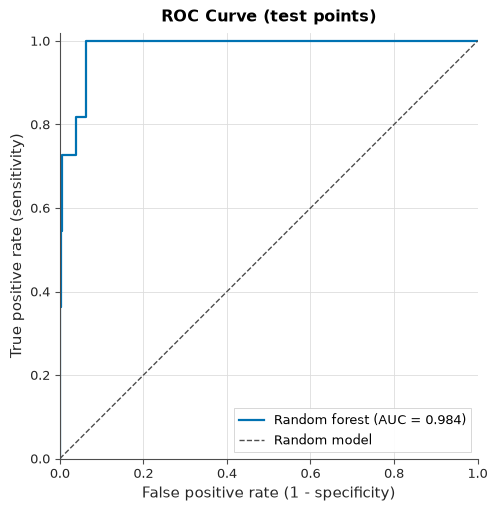

In [6]:
rf_mdl, train_acc, test_acc, test_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=make_rf_mdl(**rf_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
train_probs = species_distribution.get_positive_class_probs(rf_mdl, train_gdf[analysis_vars])
train_fpr, train_tpr, train_auc = species_distribution.calc_binary_roc_auc(train_gdf["clsid"], train_probs)
print(f"Training AUC: {train_auc:.3f}")

test_probs = species_distribution.get_positive_class_probs(rf_mdl, test_gdf[analysis_vars])
rf_metrics = species_distribution.calc_sdm_eval_metrics(test_y, test_probs, bg_scores="absences")
fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_y, test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr, tpr, auc, label="Random forest", title="ROC Curve (test points)",
    out_plot_file=os.path.join(plots_dir, "rf_testing_roc_curve.png"),
)
null_res = species_distribution.calc_null_model_auc(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    n_pres=n_train_pres, n_reps=99, observed_auc=rf_metrics["auc"], rnd_seed=42,
    plot_file=os.path.join(plots_dir, "rf_null_model_auc.png"), use_pbar=False,
)
rf_metrics["null_p95"] = null_res["null_p95"]
rf_metrics["null_p_value"] = null_res["p_value"]
pandas.Series(rf_metrics).round(3)

The random forest reaches a training AUC of 0.998: it separates its own training presences from the background almost perfectly. On the test points it has the highest AUC of the three models (0.984) and a TSS of 0.937, well above the null models (95th percentile 0.641, p = 0.01). But its Boyce index on the test points (0.681) is clearly lower than those of the logistic regression (0.940) and MaxEnt (0.865). And remember that the test points are a *random* sample of the same area, many of them a few hundred metres from training presences: exactly the situation in which a flexible model looks best. The next section checks this.

## 3. Random versus Spatial Cross-Validation

For a random forest the difference between random and spatial cross-validation is expected to be larger than for the logistic regression (notebook 02, section 11), because a forest can learn the exact conditions of the training sites, which nearby random held-out points share.

In [7]:
rnd_mdls, rnd_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    rnd_seed=42, return_scores=True, use_pbar=False,
)
rf_mdls, rf_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    make_rf_mdl(**rf_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
)
score_cols = ["train_auc", "val_auc", "val_tss", "val_boyce", "test_auc", "test_tss"]
print(rf_scores_df[["fold", "n_train", "n_val"] + score_cols].round(3))
cv_cmp_df = pandas.DataFrame(
    {
        "random CV (mean)": rnd_scores_df[score_cols].mean(),
        "spatial CV (mean)": rf_scores_df[score_cols].mean(),
        "spatial CV (sd)": rf_scores_df[score_cols].std(),
    }
)
display(cv_cmp_df.round(3))

ens_test_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, test_gdf[analysis_vars]) for mdl in rf_mdls],
    axis=0,
)
rf_ens_metrics = species_distribution.calc_sdm_eval_metrics(test_y, ens_test_probs, bg_scores="absences")
pandas.Series(rf_ens_metrics).round(3)

ROC: 0.979909090909091 - 0.9816969696969696 - 0.9852121212121212
Train: 0.9562152926099957 - 0.9572832123024348 - 0.9641178983340453
Test: 0.9554965127864496 - 0.9571570906675523 - 0.9614745931584191
Validation (out-of-fold) ROC: 0.9062366052293185 - 0.9304382421349001 - 0.9644234890698671


ROC: 0.9751515151515151 - 0.978939393939394 - 0.9801515151515152
Train: 0.9499786233433091 - 0.9690501600853789 - 0.9705317104420244
Test: 0.9501826635669213 - 0.953835934905347 - 0.972102291597476
Validation (out-of-fold) ROC: 0.8200355152776928 - 0.9311615945135019 - 0.9724039884708267
   fold  n_train   n_val  train_auc  val_auc  val_tss  val_boyce  test_auc  test_tss
0     0   4685.0  2338.0      0.998    0.931    0.874      0.270     0.979     0.891
1     1   4683.0  2340.0      0.999    0.820    0.582      0.558     0.980     0.923
2     2   4678.0  2345.0      0.999    0.972    0.915      0.618     0.975     0.917


,random CV (mean),spatial CV (mean),spatial CV (sd)
train_auc,0.999,0.999,0.001
val_auc,0.934,0.908,0.079
val_tss,0.803,0.790,0.182
val_boyce,0.725,0.482,0.186
test_auc,0.982,0.978,0.003
test_tss,0.919,0.910,0.017


auc                     0.982
threshold               0.240
tss                     0.903
sensitivity             1.000
specificity             0.903
omission_rate           0.000
commission_rate         0.097
kappa                   0.064
accuracy                0.903
balanced_accuracy       0.952
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.898
dtype: float64

This is where the random forest differs from the other two models. Its members reach a training AUC of 0.999 but an out-of-fold AUC of 0.908 with spatial blocks (0.934 with random folds), the largest gap between training and validation scores of the three models. The member whose held-out blocks contain seven presences scores only 0.820 (TSS 0.58), while its score on the common, randomly chosen test set is 0.980: random test points flatter a forest. The spatial cross-validation estimates (AUC 0.91 ± 0.08, TSS 0.79) are the honest measure of how well it predicts at new sites, and they are lower and more variable than those of the logistic regression (0.94, 0.86) and MaxEnt (0.94, 0.89).

The ensemble's test scores are AUC 0.982, TSS 0.903 and Boyce index 0.898.

In [8]:
resid_df = species_distribution.calc_residual_autocorrelation(
    rf_mdl, train_gdf, None, analysis_vars,
    dist_classes=[0, 250, 500, 1000, 1500, 2000, 3000, 4000, 6000],
    n_perms=99, rnd_seed=42,
)
resid_df[["dist_lower", "dist_upper", "morans_i", "p_value"]].round(3)

,dist_lower,dist_upper,morans_i,p_value
0,0.0,250.0,0.773,0.01
1,250.0,500.0,0.621,0.01
2,500.0,1000.0,0.422,0.01
3,1000.0,1500.0,0.261,0.01
4,1500.0,2000.0,0.193,0.01
5,2000.0,3000.0,0.090,0.01
6,3000.0,4000.0,-0.026,0.01
7,4000.0,6000.0,-0.040,0.01


The forest's residuals are less autocorrelated at short distances (Moran's I 0.77 below 250 m, against 0.92–0.93 for the other two models) because it fits the training samples more closely, which is the over-fitting seen above rather than a better description of the habitat. The autocorrelation still extends to about 3 km.

## 4. Interpreting the Random Forest

### 4.1 Response Curves

calc_grass_dist Range:	(0.0 - 6102.75341796875): Mean = 1280.7439933445144
Calculating Response Curve for 'calc_grass_dist'
flush_dist Range:	(0.0 - 2214.497802734375): Mean = 929.4367184846298
Calculating Response Curve for 'flush_dist'
impr_grass_dist Range:	(0.0 - 3739.732666015625): Mean = 1950.0651271654212
Calculating Response Curve for 'impr_grass_dist'
ledges_dist Range:	(0.0 - 5341.947265625): Mean = 355.9866565206776
Calculating Response Curve for 'ledges_dist'
rock_dist Range:	(0.0 - 6917.6005859375): Mean = 2436.267542300017
Calculating Response Curve for 'rock_dist'
scree_dist Range:	(0.0 - 3493.13623046875): Mean = 493.25894231381625
Calculating Response Curve for 'scree_dist'
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145): Mean = 2.8537858465443486
Calculating Response Curve for 'winter_temp'


,variable,min suitability,max suitability,at value,>= half max from,to
0,calc_grass_dist,0.56,0.84,1288.02,0.00,6102.75
1,flush_dist,0.17,0.85,1079.43,467.38,2214.50
2,impr_grass_dist,0.51,0.93,1710.13,0.00,3739.73
3,ledges_dist,0.07,0.84,0.00,0.00,751.63
4,rock_dist,0.45,0.88,2711.42,0.00,6917.60
5,scree_dist,0.65,0.87,579.26,0.00,3493.14
6,winter_temp,0.22,0.87,2.72,2.69,3.05


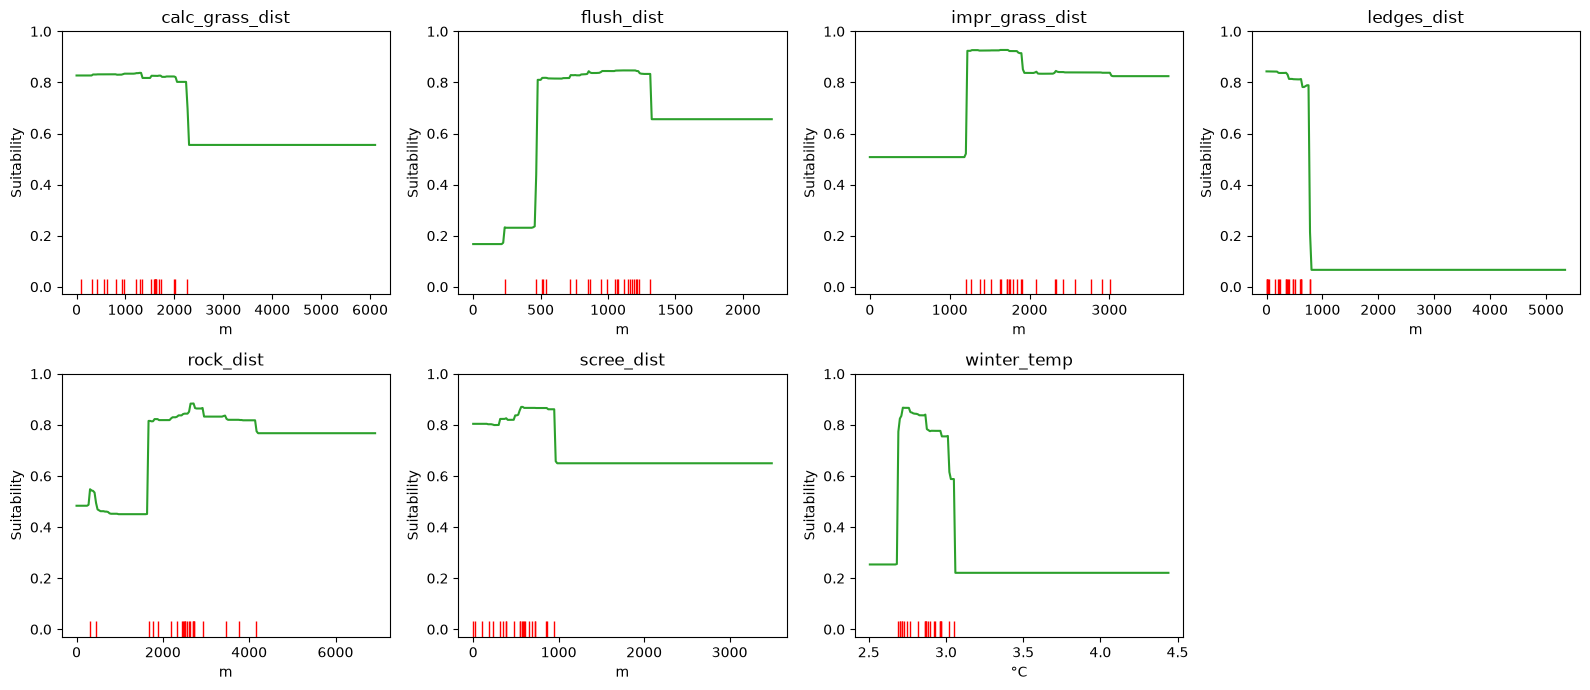

In [9]:
rf_resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=rf_mdl,
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "rf_response_curves.csv"),
    response_plots_dir=None,
    n_samples=200,
    cls_col="clsid",
)
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    ax.plot(rf_resp_df[f"{var_name}_vals"], rf_resp_df[f"{var_name}_resp"], color="tab:green")
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.0)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Suitability")
axs.flatten()[-1].axis("off")
fig.tight_layout()

half_rows = []
for var_name in analysis_vars:
    vals = rf_resp_df[f"{var_name}_vals"].to_numpy()
    resp = rf_resp_df[f"{var_name}_resp"].to_numpy()
    above = vals[resp >= resp.max() / 2]
    half_rows.append({"variable": var_name, "min suitability": resp.min(), "max suitability": resp.max(),
                      "at value": vals[resp.argmax()], ">= half max from": above.min(), "to": above.max()})
pandas.DataFrame(half_rows).round(2)

The random forest's responses are **step functions**, and their steps sit at the edges of the training presences:

* **Distance to ledges** — about 0.8 up to roughly 750 m, then a cliff to 0.07 at about 780 m, just beyond the most distant training presence (777 m). The other models fall smoothly over 500–2000 m.
* **Winter temperature** — high only between 2.69 and 3.05 °C, almost exactly the range of the training presences, and a flat 0.22–0.25 outside it on both sides.
* **Distance to flushes** — low (0.17) within about 470 m of a flush and high between 500 and 1300 m, then lower again (0.66) beyond 1300 m, the furthest training presence.
* **Improved grassland, rock, scree, calcareous grassland** — steps of 0.2–0.4 at the edges of the presence ranges (e.g. suitability drops beyond 2.3 km from calcareous grassland, and within 1.2 km of improved grassland).

In effect the forest has learnt an **envelope** around the conditions of the 23 training presences: inside the envelope suitable, outside unsuitable, whichever direction the variable goes. Some of these steps are ecologically meaningless (why should being more than 2.3 km from calcareous grassland, or more than 1.3 km from a flush, reduce suitability?); they come from the absence of presences beyond those values, not from evidence that the beetle avoids them. This is the typical behaviour of a flexible model with few presences, and the reason its spatial cross-validation scores are lower. Beyond the training data the steps stay flat: the warmest temperatures keep the suitability of 0.22, which matters for the projections (section 6).

### 4.2 Jackknife Variable Importance

In [10]:
rf_jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=make_rf_mdl(**rf_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "rf_jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(plots_dir, "rf_jackknife_auc.png"),
    cls_col="clsid",
    use_pbar=False,
)
print(f"Test AUC with all the variables: {rf_metrics['auc']:.3f}")
rf_jk_df[["roc_test_acc_leave_var_out", "roc_test_acc_only_var"]].round(3)

Test AUC with all the variables: 0.984


,roc_test_acc_leave_var_out,roc_test_acc_only_var
calc_grass_dist,0.984,0.494
flush_dist,0.975,0.859
impr_grass_dist,0.985,0.738
ledges_dist,0.968,0.830
rock_dist,0.983,0.646
scree_dist,0.981,0.517
winter_temp,0.983,0.811


On their own, the distances to flushes (0.859) and ledges (0.830) and winter temperature (0.811) are again the most informative, then improved grassland (0.738). The forest is so flexible that leaving out any single variable changes the test AUC very little (at most 0.016, for ledges): with seven correlated variables and step responses, the forest can usually rebuild the same envelope from the others.

### 4.3 SHAP

For tree models SHAP's `TreeExplainer` calculates exact SHAP values quickly. For a scikit-learn random forest classifier they are on the **probability** scale (like MaxEnt's in notebook 03, unlike the log-odds values of notebook 02). We explain the same table as in notebook 03: the 23 training presences and 177 random background points. With a tree model, a variable's SHAP values for a given value can differ from sample to sample, because of the interactions the trees have learnt; the vertical spread of the dependence (scatter) plots shows this.

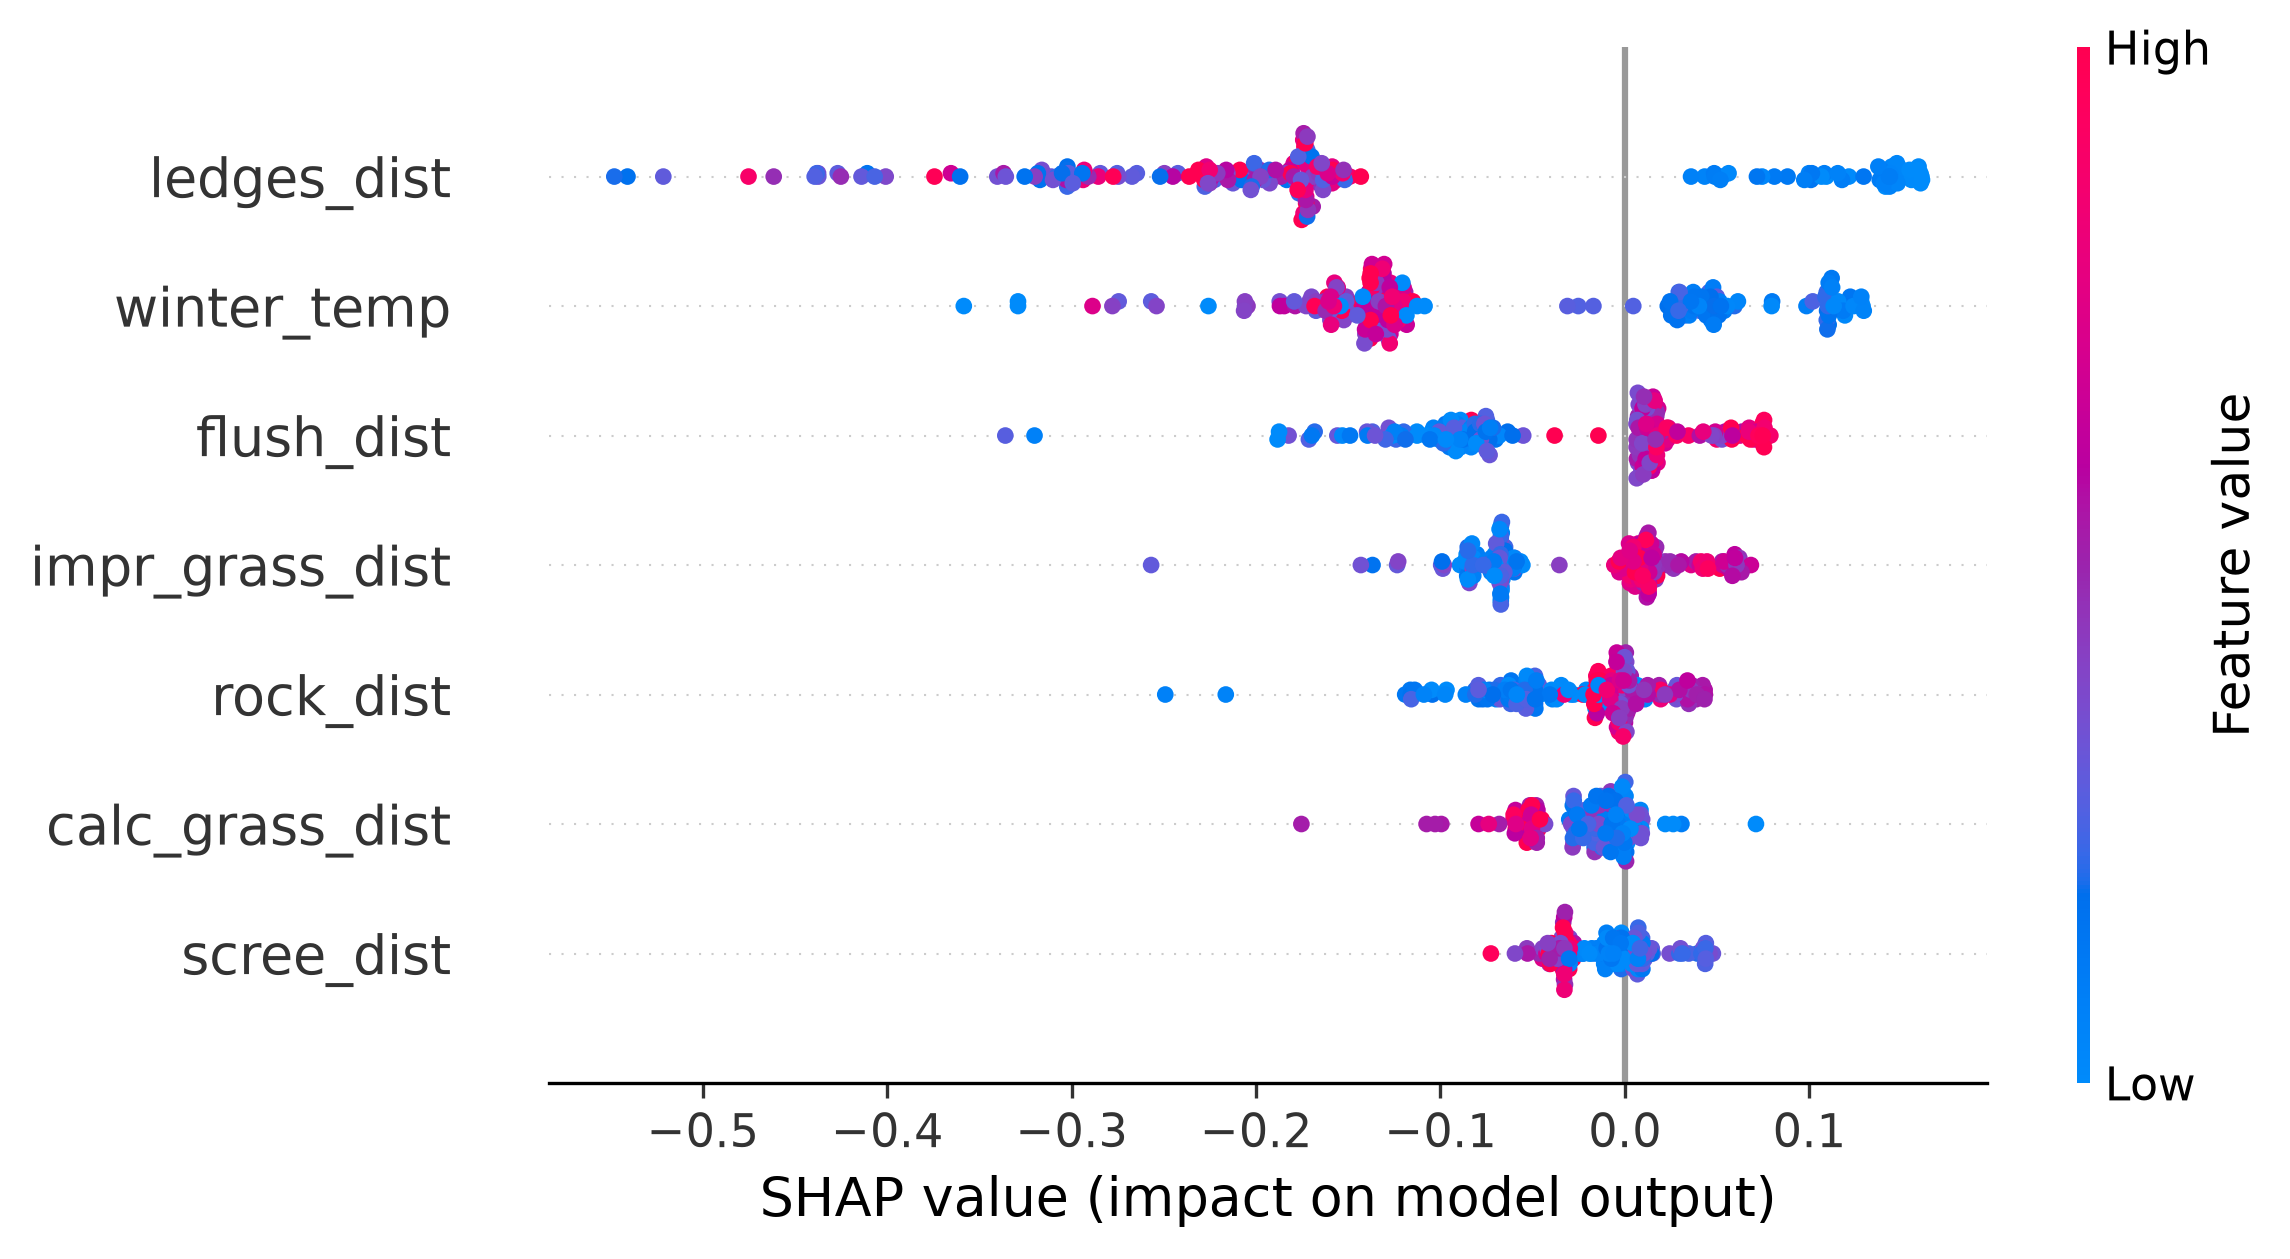

ledges_dist        0.2114
winter_temp        0.1209
flush_dist         0.0649
impr_grass_dist    0.0451
rock_dist          0.0353
calc_grass_dist    0.0226
scree_dist         0.0207
Name: mean_abs_shap, dtype: float64

In [11]:
shap_gdf = pandas.concat(
    [train_pres_gdf, train_gdf[train_gdf["clsid"] == 0].sample(n=177, random_state=42)]
)
if importlib.util.find_spec("shap") is not None:
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=rf_mdl,
        train_vec_file=shap_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        shap_summary_plot=os.path.join(plots_dir, "rf_shap_summary.png"),
        shap_scatter_plots_dir=os.path.join(plots_dir, "rf_shap_scatter"),
        use_tree_explainer=True,
    )
    display(Image(filename=os.path.join(plots_dir, "rf_shap_summary.png"), width=650))

    import shap

    tree_shap = shap.TreeExplainer(rf_mdl)(shap_gdf[analysis_vars])
    rf_shap_df = pandas.Series(
        numpy.abs(tree_shap.values[:, :, 1]).mean(axis=0), index=analysis_vars, name="mean_abs_shap"
    )
    display(rf_shap_df.sort_values(ascending=False).round(4))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The ranking is the same as for the other models: distance to ledges (mean |SHAP| 0.21) and winter temperature (0.12) far ahead, then flushes (0.06) and improved grassland (0.05). Unlike MaxEnt, every variable gets some credit, because the forest uses all of them in its splits. The scatter plots (in `outputs/sdm_RF_outs/plots/rf_shap_scatter/`) show the steps of the response curves, with a vertical spread at each value caused by the interactions the trees have learnt.

### 4.4 Sobol Sensitivity Analysis

In [12]:
if importlib.util.find_spec("SALib") is not None:
    rf_total_si, rf_first_si, rf_second_si = species_distribution.salib_sklearn_mdl_sensitivity(
        est_cls_obj=rf_mdl,
        train_vec_file=train_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        n_samples=1024,
        rnd_seed=42,
    )
    order = rf_total_si["ST"].sort_values(ascending=False).index
    display(pandas.concat([rf_total_si, rf_first_si], axis=1).loc[order].round(3))
    print("Largest second order (pairwise interaction) indices:")
    display(rf_second_si.sort_values("S2", ascending=False).head(5).round(3))
else:
    print("The SALib package is not installed, so the Sobol analysis is skipped.")

calc_grass_dist Range:	(0.0 - 6102.75341796875)
flush_dist Range:	(0.0 - 2214.497802734375)
impr_grass_dist Range:	(0.0 - 3739.732666015625)
ledges_dist Range:	(0.0 - 5341.947265625)
rock_dist Range:	(0.0 - 6917.6005859375)
scree_dist Range:	(0.0 - 3493.13623046875)
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145)


,ST,ST_conf,S1,S1_conf
ledges_dist,0.912,0.279,0.376,0.111
winter_temp,0.473,0.153,0.054,0.029
calc_grass_dist,0.055,0.018,0.004,0.020
flush_dist,0.052,0.023,-0.001,0.010
rock_dist,0.047,0.024,0.007,0.009
impr_grass_dist,0.045,0.020,0.002,0.007
scree_dist,0.011,0.005,0.011,0.010


Largest second order (pairwise interaction) indices:


,S2,S2_conf
"(ledges_dist, winter_temp)",0.432,0.358
"(calc_grass_dist, ledges_dist)",0.025,0.070
"(impr_grass_dist, ledges_dist)",0.021,0.042
"(calc_grass_dist, winter_temp)",0.020,0.045
"(flush_dist, ledges_dist)",0.018,0.048


The distance to ledges (ST 0.91, S1 0.38) and winter temperature (ST 0.47, S1 0.05) dominate, as in the other models, and they interact strongly (S2 = 0.43, with a very wide interval of ±0.36). Here the interaction can be real model structure (trees that split on temperature and then on ledges) as well as an effect of the bounded output, and the confidence intervals of the random forest's indices are the widest of the three models: its step-shaped response surface makes the variance estimates noisy. The other five variables each have ST of about 0.01–0.06.

## 5. Predict the Random Forest Suitability Map

In [13]:
rf_prob_img = os.path.join(out_dir, "Snowdon_Beetle_rf_sdm_prob.tif")
species_distribution.pred_ensemble_sklearn_mdls_prob(
    rf_mdls, valid_msk_img, 1, env_vars, analysis_vars, rf_prob_img,
    gdalformat="GTIFF", calc_stats=True, uncertainty=["std", "iqr"], use_pbar=False,
)
ens_train_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, train_gdf[analysis_vars]) for mdl in rf_mdls],
    axis=0,
)
rf_thres = {
    "max TSS": species_distribution.calc_binary_threshold(test_y, ens_test_probs, method="max_tss"),
    "10th percentile training presence": float(
        numpy.percentile(ens_train_probs[train_gdf["clsid"] == 1], 10)
    ),
}
with rasterio.open(rf_prob_img) as src:
    rf_prob_arr = src.read(1)
    pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = rf_prob_arr >= 0
thres_rows = []
for name, thres in rf_thres.items():
    test_bin = (ens_test_probs >= thres).astype(int)
    thres_rows.append({
        "threshold": name, "value": thres,
        "test sensitivity": test_bin[test_y == 1].mean(),
        "test specificity": 1 - test_bin[test_y == 0].mean(),
        "suitable area (km²)": (rf_prob_arr[valid] >= thres).sum() * pxl_km2,
        "% of study area": 100 * (rf_prob_arr[valid] >= thres).mean(),
    })
display(pandas.DataFrame(thres_rows).round(3))
rf_boyce = species_distribution.calc_boyce_index_from_raster(
    rf_prob_img, presences_vec_file, presences_vec_lyr, use_pbar=False
)
print(f"Boyce index of the map: {rf_boyce['boyce']:.3f}")

rf_bin_img = os.path.join(out_dir, "Snowdon_Beetle_rf_sdm_bin.tif")
rsgispy.imagecalc.maths.band_maths(
    rf_bin_img,
    f"prob < 0 ? 255 : (prob >= {rf_thres['max TSS']} ? 1 : 0)",
    [rsgispy.imagecalc.maths.BandDefn("prob", rf_prob_img, 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
)

,threshold,value,test sensitivity,test specificity,suitable area (km²),% of study area
0,max TSS,0.240,1.000,0.903,16.711,9.820
1,10th percentile training presence,0.891,0.545,0.997,0.557,0.327


Boyce index of the map: 0.905


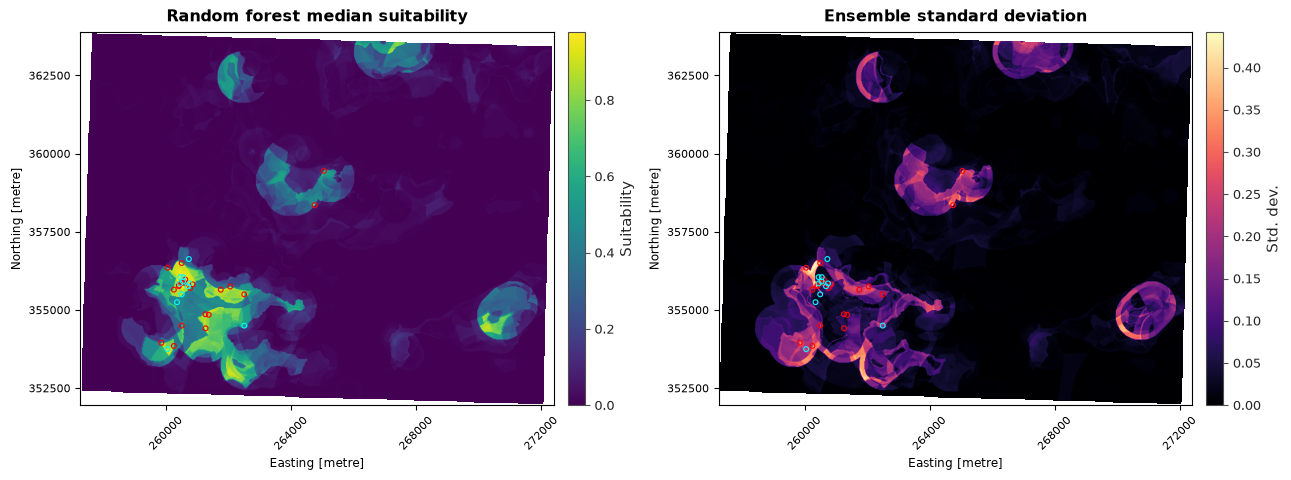

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (band, title, cmap, label) in zip(
    axs, [(1, "Random forest median suitability", "viridis", "Suitability"),
          (2, "Ensemble standard deviation", "magma", "Std. dev.")]
):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=rf_prob_img, img_band=band, title_str=title, cmap_name=cmap,
        show_colour_bar=True, cbar_label=label, show_scale_bar=False,
    )
    train_pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    test_gdf[test_gdf["clsid"] == 1].plot(ax=ax, facecolor="none", edgecolor="cyan", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The random forest predicts the same main areas as the other models, but with a patchier pattern and sharp, often circular, edges: these are the steps of the distance responses (e.g. the cliff 780 m from a ledge) drawn on the map. The ensemble standard deviation is highest along these edges, where the members put their steps in slightly different places, and over the patches without training presences.

The two thresholds are very different. The maximum-TSS threshold of the test points is low (0.240) and predicts 16.7 km² (9.8 %) suitable. The 10th percentile training presence threshold is 0.891 and predicts only 0.56 km², missing 5 of the 11 test presences (sensitivity 0.545). The reason is over-fitting: the forest predicts its own training presences with very high values (training AUC 0.998), so **a threshold calculated from the training predictions of a flexible model is far too high**. Always choose the threshold from independent (test or out-of-fold) predictions for such models. The Boyce index of the map is 0.905.

## 6. Projecting to a Warmer Climate

The same +0.5 °C and +1 °C scenarios as notebooks 02 and 03 (see notebook 02, section 16, for why these are large changes with this temperature raster). Like MaxEnt's clamping, a random forest predicts beyond the training range as if the variable were at the end of its range (no tree has a split beyond it).

In [15]:
scen_rows = []
for warming in [0.5, 1.0]:
    tag = f"plus{warming:.1f}".replace(".", "_")
    warm_env_vars = species_distribution.copy_env_vars_for_scenario(
        env_vars, {"winter_temp": os.path.join(lr_dir, f"Mean_Winter_Temp_{tag}.tif")}
    )
    warm_prob_img = os.path.join(out_dir, f"Snowdon_Beetle_rf_sdm_prob_{tag}.tif")
    species_distribution.pred_ensemble_sklearn_mdls_prob(
        rf_mdls, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_prob_img,
        calc_stats=True, use_pbar=False,
    )
    warm_bin_img = os.path.join(out_dir, f"Snowdon_Beetle_rf_sdm_bin_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_bin_img,
        f"prob < 0 ? 255 : (prob >= {rf_thres['max TSS']} ? 1 : 0)",
        [rsgispy.imagecalc.maths.BandDefn("prob", warm_prob_img, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
    )
    summary = species_distribution.calc_range_change(
        rf_bin_img, warm_bin_img, os.path.join(out_dir, f"rf_range_change_{tag}.tif"),
        in_msk_img=valid_msk_img, use_pbar=False,
    )
    scen_rows.append(
        {
            "warming (°C)": warming,
            "current (km²)": summary["current_area"] / 1e6,
            "scenario (km²)": summary["future_area"] / 1e6,
            "lost (km²)": summary["area_lost"] / 1e6,
            "gained (km²)": summary["area_gained"] / 1e6,
            "stable (km²)": summary["area_stable"] / 1e6,
            "net change (%)": summary["pct_net_change"],
        }
    )
scen_df = pandas.DataFrame(scen_rows)
scen_df.round(2)

,warming (°C),current (km²),scenario (km²),lost (km²),gained (km²),stable (km²),net change (%)
0,0.5,16.71,5.95,10.94,0.19,5.77,-64.38
1,1.0,16.71,5.34,11.37,0.00,5.34,-68.03


Unlike the logistic regression and MaxEnt, the random forest keeps part of the suitable area under both scenarios: 6.0 km² at +0.5 °C and still 5.3 km² at +1 °C (−64 % and −68 %), all on ground that is suitable now. The reason is the flat floor of its temperature response: outside the training range of the presences, the forest predicts 0.22–0.25 from temperature, and its maximum-TSS threshold is low (0.240), so pixels close to ledges and away from flushes can stay just above the threshold whatever the temperature. The forest does not "know" that warmer means worse beyond the presences' range; it only knows that the presences are not there. Notebook 05 compares the three projections.

## 7. Save the Results for the Comparison

In [16]:
rsgispy.tools.jsonio.write_dict_to_json(
    {key: float(val) for key, val in rf_metrics.items()}, os.path.join(out_dir, "rf_test_metrics.json")
)
rsgispy.tools.jsonio.write_dict_to_json(rf_thres, os.path.join(out_dir, "rf_thresholds.json"))
pandas.DataFrame({"clsid": test_y, "ens_prob": ens_test_probs}).to_csv(
    os.path.join(out_dir, "rf_test_scores.csv"), index=False
)
rf_scores_df.to_csv(os.path.join(out_dir, "rf_spatial_cv_scores.csv"), index=False)
scen_df.to_csv(os.path.join(out_dir, "rf_scenarios.csv"), index=False)
if importlib.util.find_spec("SALib") is not None:
    rf_total_si.to_csv(os.path.join(out_dir, "rf_sobol_ST.csv"), index_label="variable")
if importlib.util.find_spec("shap") is not None:
    rf_shap_df.to_csv(os.path.join(out_dir, "rf_shap_mean_abs.csv"), index_label="variable")
sorted(os.listdir(out_dir))

['Snowdon_Beetle_rf_sdm_bin.tif',
 'Snowdon_Beetle_rf_sdm_bin_plus0_5.tif',
 'Snowdon_Beetle_rf_sdm_bin_plus1_0.tif',
 'Snowdon_Beetle_rf_sdm_prob.tif',
 'Snowdon_Beetle_rf_sdm_prob_plus0_5.tif',
 'Snowdon_Beetle_rf_sdm_prob_plus1_0.tif',
 'plots',
 'rf_jackknife_var_importance.csv',
 'rf_params.json',
 'rf_range_change_plus0_5.tif',
 'rf_range_change_plus1_0.tif',
 'rf_response_curves.csv',
 'rf_scenarios.csv',
 'rf_shap_mean_abs.csv',
 'rf_sobol_ST.csv',
 'rf_spatial_cv_scores.csv',
 'rf_test_metrics.json',
 'rf_test_scores.csv',
 'rf_thresholds.json']